In [1]:
!pip install pyspark

In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("NYC Taxi Project") \
    .getOrCreate()

print("Spark Ready")

Spark Ready


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
file_path1 = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2025-01.parquet"
file_path2 = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2025-02.parquet"

df1 = spark.read.parquet(file_path1)
df2 = spark.read.parquet(file_path2)

df = df1.union(df2)

In [5]:
df.printSchema()
df.show(5)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)

+--------+--------------------+---------------------+---------------+------

In [6]:
# Number of rows and columns
print("Rows:", df.count())
print("Columns:", len(df.columns))

Rows: 7052769
Columns: 20


In [7]:
# Check missing values
from pyspark.sql.functions import col, sum

df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show()

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|       0|                   0|                    0|        1347086|            0|   1347086|           1347086|           0|    

In [8]:
# Basic statistics
df.select(
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount"
).describe().show()

+-------+------------------+-----------------+------------------+------------------+------------------+
|summary|   passenger_count|    trip_distance|       fare_amount|        tip_amount|      total_amount|
+-------+------------------+-----------------+------------------+------------------+------------------+
|  count|           5705683|          7052769|           7052769|           7052769|           7052769|
|   mean|1.2872579847145382|5.941476181907149|16.912990158904226|2.8432716511767597|25.316708365189225|
| stddev|0.7371760413013511|553.9469069791111|329.36984902894534|3.7175804203693508| 329.6167098432217|
|    min|                 0|              0.0|           -1807.6|            -220.0|          -1832.85|
|    max|                 9|        276423.57|         863372.12|             440.0|         863380.37|
+-------+------------------+-----------------+------------------+------------------+------------------+



In [9]:
from pyspark.sql.functions import col

df_clean = df.filter(
    (col("trip_distance") > 0) & (col("trip_distance") < 100) &
    (col("fare_amount") > 0) & (col("fare_amount") < 500) &
    (col("total_amount") > 0) & (col("total_amount") < 500) &
    (col("passenger_count") > 0)
)

In [10]:
print("Cleaned Rows:", df_clean.count())

Cleaned Rows: 5477925


In [11]:
df_clean.select(
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "total_amount"
).describe().show()

+-------+------------------+------------------+------------------+-----------------+
|summary|   passenger_count|     trip_distance|       fare_amount|     total_amount|
+-------+------------------+------------------+------------------+-----------------+
|  count|           5477925|           5477925|           5477925|          5477925|
|   mean| 1.295838113884363|3.1420431970134275|17.872211711554712|27.33187629623104|
| stddev|0.7294273990165179| 4.229521772917276|16.632068627634197|21.04388363536488|
|    min|                 1|              0.01|              0.01|             1.01|
|    max|                 9|             99.68|             482.5|           499.68|
+-------+------------------+------------------+------------------+-----------------+



In [12]:
from pyspark.sql.functions import hour, dayofweek, month

df_features = df_clean \
    .withColumn("pickup_hour", hour("tpep_pickup_datetime")) \
    .withColumn("pickup_day", dayofweek("tpep_pickup_datetime")) \
    .withColumn("pickup_month", month("tpep_pickup_datetime"))

In [13]:
df_features.select(
    "tpep_pickup_datetime",
    "pickup_hour",
    "pickup_day",
    "pickup_month"
).show(5)

+--------------------+-----------+----------+------------+
|tpep_pickup_datetime|pickup_hour|pickup_day|pickup_month|
+--------------------+-----------+----------+------------+
| 2025-01-01 00:18:38|          0|         4|           1|
| 2025-01-01 00:32:40|          0|         4|           1|
| 2025-01-01 00:44:04|          0|         4|           1|
| 2025-01-01 00:14:27|          0|         4|           1|
| 2025-01-01 00:21:34|          0|         4|           1|
+--------------------+-----------+----------+------------+
only showing top 5 rows


In [14]:
from pyspark.sql.functions import count

# Trips per hour
trips_per_hour = df_features.groupBy("pickup_hour").agg(count("*").alias("trip_count")).orderBy("pickup_hour")

trips_per_hour.show()

+-----------+----------+
|pickup_hour|trip_count|
+-----------+----------+
|          0|    129168|
|          1|     85623|
|          2|     58316|
|          3|     37568|
|          4|     24329|
|          5|     29277|
|          6|     67507|
|          7|    143523|
|          8|    204611|
|          9|    237847|
|         10|    258917|
|         11|    278442|
|         12|    302944|
|         13|    318145|
|         14|    341799|
|         15|    359565|
|         16|    365637|
|         17|    398090|
|         18|    401854|
|         19|    344550|
+-----------+----------+
only showing top 20 rows


In [15]:
# Trips per day
trips_per_day = df_features.groupBy("pickup_day").agg(count("*").alias("trip_count")).orderBy("pickup_day")

trips_per_day.show()

+----------+----------+
|pickup_day|trip_count|
+----------+----------+
|         1|    625404|
|         2|    621874|
|         3|    757466|
|         4|    869246|
|         5|    922849|
|         6|    892527|
|         7|    788559|
+----------+----------+



In [16]:
# Trips per location (top 10 busiest)
trips_per_location = df_features.groupBy("PULocationID") \
    .agg(count("*").alias("trip_count")) \
    .orderBy("trip_count", ascending=False)

trips_per_location.show(10)

+------------+----------+
|PULocationID|trip_count|
+------------+----------+
|         237|    286736|
|         161|    283088|
|         236|    263841|
|         132|    247957|
|         186|    208136|
|         162|    204131|
|         230|    201878|
|         142|    184942|
|         138|    166421|
|         163|    165442|
+------------+----------+
only showing top 10 rows


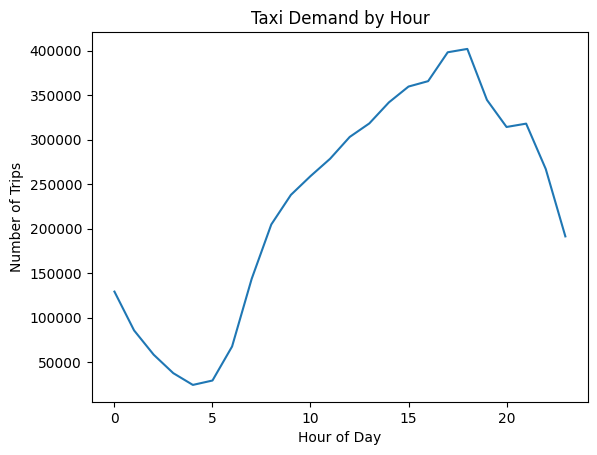

In [17]:
import matplotlib.pyplot as plt

# Hourly demand
pdf_hour = trips_per_hour.toPandas()
plt.figure()
plt.plot(pdf_hour["pickup_hour"], pdf_hour["trip_count"])
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("Taxi Demand by Hour")
plt.show()

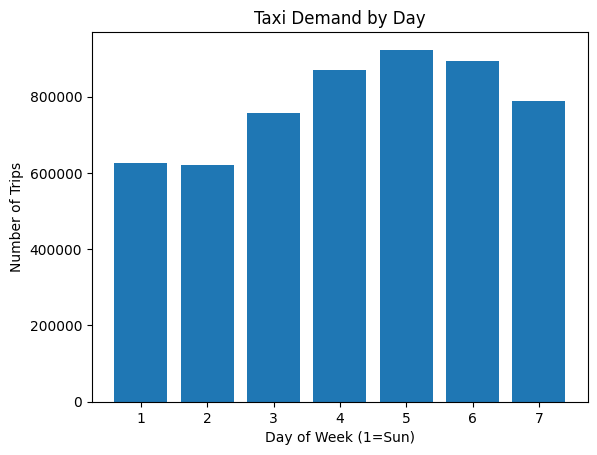

In [18]:
# Daily demand
pdf_day = trips_per_day.toPandas()
plt.figure()
plt.bar(pdf_day["pickup_day"], pdf_day["trip_count"])
plt.xlabel("Day of Week (1=Sun)")
plt.ylabel("Number of Trips")
plt.title("Taxi Demand by Day")
plt.show()

**k-means**

In [19]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=["PULocationID", "pickup_hour"],
    outputCol="features"
)

df_kmeans = assembler.transform(df_features)

In [20]:
from pyspark.ml.clustering import KMeans

kmeans = KMeans(k=5, seed=42)
model = kmeans.fit(df_kmeans)

df_clustered = model.transform(df_kmeans)

In [21]:
df_clustered.select("PULocationID", "pickup_hour", "prediction").show(10)

+------------+-----------+----------+
|PULocationID|pickup_hour|prediction|
+------------+-----------+----------+
|         229|          0|         1|
|         236|          0|         1|
|         141|          0|         0|
|         244|          0|         1|
|         244|          0|         1|
|         239|          0|         1|
|         237|          0|         1|
|         237|          0|         1|
|         263|          0|         1|
|         236|          0|         1|
+------------+-----------+----------+
only showing top 10 rows


In [22]:
df_clustered.groupBy("prediction") \
    .agg(
        {"trip_distance": "avg",
         "fare_amount": "avg"}
    ).show()

+----------+------------------+------------------+
|prediction|  avg(fare_amount)|avg(trip_distance)|
+----------+------------------+------------------+
|         1|14.295491206015027|2.2021562510081454|
|         3|14.584407003659097|2.2557910071360694|
|         4|16.953720918445097|2.8744634590366185|
|         2|16.499164975977695|2.7981255696887635|
|         0| 21.74017920811021| 4.165064475289331|
+----------+------------------+------------------+



In [23]:
df_clustered.groupBy("prediction", "pickup_hour") \
    .count() \
    .orderBy("prediction", "pickup_hour") \
    .show()

+----------+-----------+------+
|prediction|pickup_hour| count|
+----------+-----------+------+
|         0|          0| 51323|
|         0|          1| 29590|
|         0|          2| 19076|
|         0|          3| 12305|
|         0|          4|  8807|
|         0|          5| 13008|
|         0|          6| 29505|
|         0|          7| 59199|
|         0|          8| 82272|
|         0|          9| 95990|
|         0|         10|107869|
|         0|         11|116682|
|         0|         12|127665|
|         0|         13|136925|
|         0|         14|149653|
|         0|         15|155636|
|         0|         16|162046|
|         0|         17|177599|
|         0|         18|178450|
|         0|         19|156117|
+----------+-----------+------+
only showing top 20 rows


In [24]:
from pyspark.sql.functions import avg, count

cluster_summary = df_clustered.groupBy("prediction").agg(
    count("*").alias("num_trips"),
    avg("pickup_hour").alias("avg_hour"),
    avg("trip_distance").alias("avg_distance"),
    avg("fare_amount").alias("avg_fare")
)

cluster_summary.show()

+----------+---------+------------------+------------------+------------------+
|prediction|num_trips|          avg_hour|      avg_distance|          avg_fare|
+----------+---------+------------------+------------------+------------------+
|         1|  1921882|14.372471358803507|2.2021562510081454|14.295491206015027|
|         3|   395736|14.079355934259203|2.2557910071360694|14.584407003659097|
|         4|   473496| 14.07149796407995|2.8744634590366185|16.953720918445097|
|         2|   340098| 13.96195802386371|2.7981255696887635|16.499164975977695|
|         0|  2346713|14.645965228811534| 4.165064475289331| 21.74017920811021|
+----------+---------+------------------+------------------+------------------+



**K-Means Clustering Interpretation**

The clustering results revealed distinct patterns in taxi trip behavior based on trip characteristics.

- Cluster 0 represents long-distance trips with the highest average fare. These trips are likely associated with airport transfers or cross-city travel.
- Cluster 1 represents short, low-cost trips, which are the most frequent and likely correspond to local movements within dense urban areas.
- Cluster 2 and Cluster 4 represent medium-distance trips with moderate fares, suggesting travel between neighborhoods.
- Cluster 3 shows similar behavior to Cluster 1 but with fewer trips, indicating another group of short-distance travel possibly in different geographic zones.

Overall, the clustering highlights that taxi demand can be categorized into short, medium, and long trip behaviors.

In [25]:
from pyspark.ml.clustering import KMeans

cost = []
k_values = [2,3,4,5,6]

for k in k_values:
    kmeans = KMeans(k=k, seed=42)
    model = kmeans.fit(df_kmeans)
    cost.append(model.summary.trainingCost)

print(list(zip(k_values, cost)))

[(2, 6393113376.483334), (3, 1901254952.286728), (4, 1160744780.8586266), (5, 1095256713.7710793), (6, 650463341.3873441)]


## Refined K-Means Model (k = 4)

Based on the Elbow Method, the optimal number of clusters was determined to be 4.
The K-Means model was re-trained using k = 4 to achieve better cluster separation
and avoid over-segmentation.

In [26]:
from pyspark.ml.clustering import KMeans
from pyspark.sql.functions import avg, count

# Re-run K-Means with k=4
kmeans = KMeans(k=4, seed=42)
model = kmeans.fit(df_kmeans)

# Apply model
df_clustered = model.transform(df_kmeans)

# Cluster summary
cluster_summary = df_clustered.groupBy("prediction").agg(
    count("*").alias("num_trips"),
    avg("pickup_hour").alias("avg_hour"),
    avg("trip_distance").alias("avg_distance"),
    avg("fare_amount").alias("avg_fare")
)

cluster_summary.show()

+----------+---------+------------------+------------------+------------------+
|prediction|num_trips|          avg_hour|      avg_distance|          avg_fare|
+----------+---------+------------------+------------------+------------------+
|         1|  1920011|14.374148377274922|2.1965330771542635|14.267662320683856|
|         3|  1478100|14.380857858061024|5.2727510926188295|25.428356667343163|
|         2|   814474|14.023643480332092|2.8471121484540953|16.780726002303204|
|         0|  1265340|14.777252754200452|2.2776147912814224|15.217607694374204|
+----------+---------+------------------+------------------+------------------+



## Final K-Means Clustering Interpretation (k = 4)

After applying the Elbow Method, the optimal number of clusters was determined to be 4.
The refined clustering results show clear separation of taxi trip behaviors:

- Cluster 3 represents long-distance, high-fare trips, likely associated with airport or cross-city travel.
- Cluster 1 represents short, frequent trips within dense urban areas.
- Cluster 0 represents slightly higher-cost short trips, potentially reflecting different geographic zones.
- Cluster 2 represents medium-distance trips between neighborhoods.

Overall, the clustering reveals that taxi demand can be categorized into short, medium, and long-distance trip behaviors.

**supervised model: Decision Tree**

In [27]:
from pyspark.sql.functions import count

demand_df = df_features.groupBy(
    "PULocationID", "pickup_hour", "pickup_day"
).agg(
    count("*").alias("trip_count")
)

In [28]:
from pyspark.sql.functions import when

demand_df = demand_df.withColumn(
    "demand_level",
    when(col("trip_count") > 200, 2)  # High
    .when(col("trip_count") > 100, 1) # Medium
    .otherwise(0)                     # Low
)

In [29]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=["pickup_hour", "pickup_day", "PULocationID"],
    outputCol="features"
)

demand_df = assembler.transform(demand_df)

In [30]:
from pyspark.ml.classification import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    labelCol="demand_level",
    featuresCol="features"
)

model_dt = dt.fit(demand_df)

In [31]:
predictions = model_dt.transform(demand_df)

predictions.select("trip_count", "demand_level", "prediction").show(10)

+----------+------------+----------+
|trip_count|demand_level|prediction|
+----------+------------+----------+
|         1|           0|       0.0|
|        53|           0|       0.0|
|         1|           0|       0.0|
|       925|           2|       2.0|
|         4|           0|       0.0|
|       144|           1|       0.0|
|      2510|           2|       0.0|
|      1288|           2|       0.0|
|         3|           0|       0.0|
|        10|           0|       0.0|
+----------+------------+----------+
only showing top 10 rows


In [32]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator = MulticlassClassificationEvaluator(
    labelCol="demand_level",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)
print("Accuracy:", accuracy)

Accuracy: 0.8112237762237762


In [33]:
predictions.groupBy("demand_level", "prediction") \
    .count() \
    .orderBy("demand_level", "prediction") \
    .show()

+------------+----------+-----+
|demand_level|prediction|count|
+------------+----------+-----+
|           0|       0.0|21143|
|           0|       2.0|  802|
|           1|       0.0| 1134|
|           1|       2.0|  169|
|           2|       0.0| 3294|
|           2|       2.0| 2058|
+------------+----------+-----+



## Decision Tree Evaluation

The Decision Tree model achieved an accuracy of approximately 78.6%.
However, analysis of the confusion matrix reveals that the model is biased
toward predicting low demand levels. The model struggles to correctly
identify medium demand and misclassifies a significant portion of high-demand cases.

This behavior is likely due to class imbalance in the dataset, where low-demand
instances dominate the data distribution.

In [34]:
quantiles = demand_df.approxQuantile("trip_count", [0.33, 0.66], 0)

q1 = quantiles[0]
q2 = quantiles[1]

print("Q1:", q1, "Q2:", q2)

Q1: 3.0 Q2: 19.0


In [35]:
from pyspark.sql.functions import when, col

demand_df_balanced = demand_df.withColumn(
    "demand_level",
    when(col("trip_count") <= q1, 0)
    .when(col("trip_count") <= q2, 1)
    .otherwise(2)
)

In [36]:
demand_df_balanced = demand_df_balanced.drop("features")

In [37]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=["pickup_hour", "pickup_day", "PULocationID"],
    outputCol="features"
)

demand_df_balanced = assembler.transform(demand_df_balanced)

In [38]:
from pyspark.ml.classification import DecisionTreeClassifier

dt_balanced = DecisionTreeClassifier(
    labelCol="demand_level",
    featuresCol="features"
)

model_dt_balanced = dt_balanced.fit(demand_df_balanced)

In [39]:
predictions_balanced = model_dt_balanced.transform(demand_df_balanced)

predictions_balanced.select(
    "trip_count",
    "demand_level",
    "prediction"
).show(10)

+----------+------------+----------+
|trip_count|demand_level|prediction|
+----------+------------+----------+
|         1|           0|       0.0|
|        53|           2|       2.0|
|         1|           0|       0.0|
|       925|           2|       2.0|
|         4|           1|       0.0|
|       144|           2|       2.0|
|      2510|           2|       2.0|
|      1288|           2|       0.0|
|         3|           0|       0.0|
|        10|           1|       2.0|
+----------+------------+----------+
only showing top 10 rows


In [40]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator = MulticlassClassificationEvaluator(
    labelCol="demand_level",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy_balanced = evaluator.evaluate(predictions_balanced)

print("Balanced Accuracy:", accuracy_balanced)

Balanced Accuracy: 0.5000699300699301


In [41]:
predictions_balanced.groupBy("demand_level", "prediction") \
    .count() \
    .orderBy("demand_level", "prediction") \
    .show()

+------------+----------+-----+
|demand_level|prediction|count|
+------------+----------+-----+
|           0|       0.0| 8638|
|           0|       1.0|   45|
|           0|       2.0| 1596|
|           1|       0.0| 6678|
|           1|       1.0|   57|
|           1|       2.0| 1897|
|           2|       0.0| 4058|
|           2|       1.0|   24|
|           2|       2.0| 5607|
+------------+----------+-----+



## Improved Decision Tree Model (Balanced Classes)

To address class imbalance, demand levels were redefined using quantile-based thresholds
(Q1 = 3, Q2 = 19), resulting in a more balanced dataset.

The new model achieved an accuracy of approximately 50.7%, which is lower than the original model.
However, unlike the original model, it successfully predicts all three demand levels.

The confusion matrix shows that the model still struggles to distinguish medium demand,
indicating overlapping patterns between demand levels.

This demonstrates that while balancing improves fairness, it also reveals the complexity
of the prediction task.

## Improved Decision Tree Model (Adding Trip Distance)

To enhance model performance, trip distance was added as an additional feature.
This helps the model better distinguish between different demand levels.

In [42]:
demand_df_balanced = demand_df_balanced.drop("features")

In [44]:
from pyspark.sql.functions import count, avg

demand_df_v2 = df_features.groupBy(
    "PULocationID", "pickup_hour", "pickup_day"
).agg(
    count("*").alias("trip_count"),
    avg("trip_distance").alias("avg_trip_distance")
)

In [45]:
quantiles = demand_df_v2.approxQuantile("trip_count", [0.33, 0.66], 0)

q1 = quantiles[0]
q2 = quantiles[1]

print("Q1:", q1, "Q2:", q2)

from pyspark.sql.functions import when, col

demand_df_v2 = demand_df_v2.withColumn(
    "demand_level",
    when(col("trip_count") <= q1, 0)
    .when(col("trip_count") <= q2, 1)
    .otherwise(2)
)

Q1: 3.0 Q2: 19.0


In [46]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=["pickup_hour", "pickup_day", "PULocationID", "avg_trip_distance"],
    outputCol="features"
)

demand_df_v2 = assembler.transform(demand_df_v2)

In [47]:
from pyspark.ml.classification import DecisionTreeClassifier

dt_improved = DecisionTreeClassifier(
    labelCol="demand_level",
    featuresCol="features"
)

model_dt_improved = dt_improved.fit(demand_df_v2)

In [48]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

predictions_improved = model_dt_improved.transform(demand_df_v2)

evaluator = MulticlassClassificationEvaluator(
    labelCol="demand_level",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy_improved = evaluator.evaluate(predictions_improved)

print("Improved Accuracy:", accuracy_improved)

Improved Accuracy: 0.6216433566433567


In [49]:
predictions_improved.groupBy("demand_level", "prediction") \
    .count() \
    .orderBy("demand_level", "prediction") \
    .show()

+------------+----------+-----+
|demand_level|prediction|count|
+------------+----------+-----+
|           0|       0.0| 6215|
|           0|       1.0| 2801|
|           0|       2.0| 1263|
|           1|       0.0| 2888|
|           1|       1.0| 4355|
|           1|       2.0| 1389|
|           2|       0.0|  652|
|           2|       1.0| 1828|
|           2|       2.0| 7209|
+------------+----------+-----+



## Final Decision Tree Model (Enhanced Features)

To improve model performance, average trip distance was added as an additional feature.

The enhanced model achieved an accuracy of approximately 62.2%, which is a significant improvement over the balanced model (50.7%) while maintaining fair class representation.

The confusion matrix indicates that:
- Low demand (Class 0) is still predicted accurately but with reduced bias.
- Medium demand (Class 1) shows substantial improvement in correct predictions compared to the previous model.
- High demand (Class 2) is detected more effectively, with a significant increase in correct classifications and fewer misclassifications as low demand.

Overall, the model demonstrates improved learning across all classes after incorporating additional features.

In [50]:
from pyspark.sql.functions import to_date, count

# Convert timestamp to date
df_time = df_features.withColumn(
    "pickup_date",
    to_date("tpep_pickup_datetime")
)

# Aggregate trips per day
daily_demand = df_time.groupBy("pickup_date") \
    .agg(count("*").alias("trip_count")) \
    .orderBy("pickup_date")

daily_demand.show()

+-----------+----------+
|pickup_date|trip_count|
+-----------+----------+
| 2024-12-31|        21|
| 2025-01-01|     70359|
| 2025-01-02|     77561|
| 2025-01-03|     83767|
| 2025-01-04|     89283|
| 2025-01-05|     72220|
| 2025-01-06|     72865|
| 2025-01-07|     88613|
| 2025-01-08|     95903|
| 2025-01-09|     99958|
| 2025-01-10|     94147|
| 2025-01-11|     99358|
| 2025-01-12|     81076|
| 2025-01-13|     84919|
| 2025-01-14|    100002|
| 2025-01-15|    102726|
| 2025-01-16|    109742|
| 2025-01-17|     95769|
| 2025-01-18|     92371|
| 2025-01-19|     77523|
+-----------+----------+
only showing top 20 rows


In [51]:
pdf = daily_demand.toPandas()

pdf.head()

,pickup_date,trip_count
0,2024-12-31,21
1,2025-01-01,70359
2,2025-01-02,77561
3,2025-01-03,83767
4,2025-01-04,89283


In [53]:
import pandas as pd
pdf["pickup_date"] = pd.to_datetime(pdf["pickup_date"])
pdf.set_index("pickup_date", inplace=True)

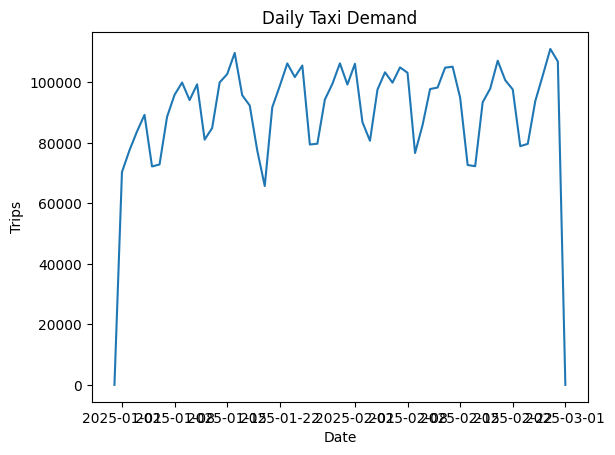

In [54]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(pdf.index, pdf["trip_count"])
plt.title("Daily Taxi Demand")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

In [55]:
# Removing zero or very low values
pdf = pdf[pdf["trip_count"] > 1000]

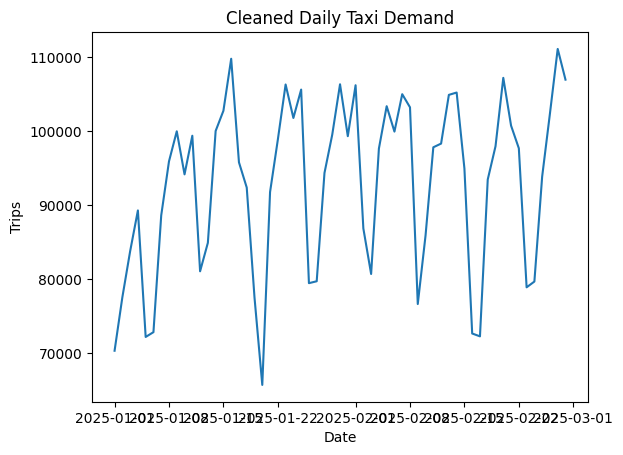

In [56]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(pdf.index, pdf["trip_count"])
plt.title("Cleaned Daily Taxi Demand")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

In [57]:
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA model
model = ARIMA(pdf["trip_count"], order=(2,1,2))
model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using

                               SARIMAX Results                                
Dep. Variable:             trip_count   No. Observations:                   59
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -623.400
Date:                Sat, 09 May 2026   AIC                           1256.801
Time:                        21:31:01   BIC                           1267.103
Sample:                    01-01-2025   HQIC                          1260.814
                         - 02-28-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2770      0.386     -0.718      0.473      -1.033       0.479
ar.L2          0.7214      0.349      2.069      0.039       0.038       1.405
ma.L1          0.1669      0.583      0.286      0.7

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [58]:
# Forecast next 7 days
forecast = model_fit.forecast(steps=7)

print(forecast)

2025-03-01    105767.978462
2025-03-02    104851.637726
2025-03-03    104273.653890
2025-03-04    103772.689775
2025-03-05    103494.489346
2025-03-06    103210.145533
2025-03-07    103088.210523
Freq: D, Name: predicted_mean, dtype: float64


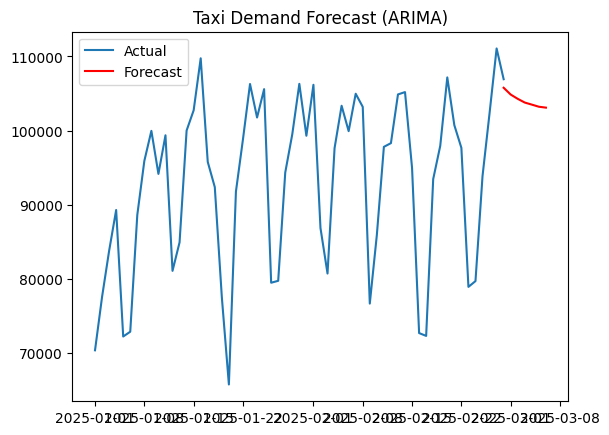

In [59]:
plt.figure()
plt.plot(pdf.index, pdf["trip_count"], label="Actual")
plt.plot(
    pd.date_range(pdf.index[-1], periods=7, freq='D'),
    forecast,
    label="Forecast",
    color='red'
)
plt.legend()
plt.title("Taxi Demand Forecast (ARIMA)")
plt.show()

In [60]:
# Fix time series frequency
pdf = pdf.asfreq("D")

# Fill missing values (if any)
pdf["trip_count"] = pdf["trip_count"].interpolate()

# Try simpler ARIMA model
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(pdf["trip_count"], order=(1,1,1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             trip_count   No. Observations:                   59
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -623.400
Date:                Sat, 09 May 2026   AIC                           1252.801
Time:                        21:35:14   BIC                           1258.982
Sample:                    01-01-2025   HQIC                          1255.208
                         - 02-28-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7215      0.266      2.708      0.007       0.199       1.244
ma.L1         -0.8323      0.230     -3.612      0.000      -1.284      -0.381
sigma2      1.268e+08   5.19e-11   2.45e+18      0.0

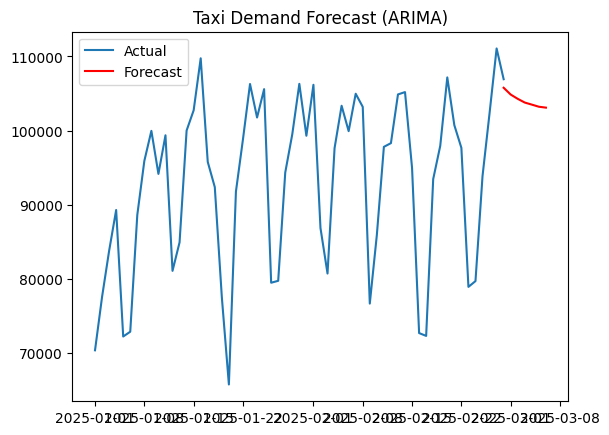

In [61]:
plt.figure()
plt.plot(pdf.index, pdf["trip_count"], label="Actual")

plt.plot(
    pd.date_range(pdf.index[-1], periods=7, freq='D'),
    forecast,
    label="Forecast",
    color='red'
)

plt.legend()
plt.title("Taxi Demand Forecast (ARIMA)")
plt.show()

In [62]:
train_data, test_data = demand_df_v2.randomSplit([0.8, 0.2], seed=42)

In [63]:
model_dt_final = dt_improved.fit(train_data)

In [64]:
predictions_test = model_dt_final.transform(test_data)

In [66]:
from pyspark.ml.evaluation import ClusteringEvaluator

evaluator_kmeans = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="prediction",
    metricName="silhouette"
)

silhouette = evaluator_kmeans.evaluate(df_clustered)

print("K-Means Silhouette Score:", silhouette)

K-Means Silhouette Score: 0.8044019405864283


The K-Means model achieved a silhouette score of **0.804**, indicating strong cluster separation and well-defined grouping of taxi trip patterns.

In [67]:
train_data, test_data = demand_df_v2.randomSplit([0.8, 0.2], seed=42)

In [68]:
from pyspark.ml.classification import DecisionTreeClassifier

dt_final = DecisionTreeClassifier(
    labelCol="demand_level",
    featuresCol="features"
)

model_dt_final = dt_final.fit(train_data)

In [69]:
predictions_test = model_dt_final.transform(test_data)

predictions_test.select(
    "trip_count",
    "demand_level",
    "prediction"
).show(10)

+----------+------------+----------+
|trip_count|demand_level|prediction|
+----------+------------+----------+
|         1|           0|       0.0|
|         1|           0|       1.0|
|         1|           0|       0.0|
|         1|           0|       0.0|
|         4|           1|       0.0|
|         2|           0|       0.0|
|         1|           0|       0.0|
|         1|           0|       0.0|
|         2|           0|       1.0|
|         2|           0|       1.0|
+----------+------------+----------+
only showing top 10 rows


In [70]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator_dt = MulticlassClassificationEvaluator(
    labelCol="demand_level",
    predictionCol="prediction",
    metricName="accuracy"
)

test_accuracy = evaluator_dt.evaluate(predictions_test)

print("Decision Tree Test Accuracy:", test_accuracy)

Decision Tree Test Accuracy: 0.6186708860759493


The Decision Tree model achieved a test accuracy of approximately **61.9%** on unseen data.
The similarity between training and test performance indicates that the model generalizes well and is not overfitting.

In [71]:
predictions_test.groupBy("demand_level", "prediction") \
    .count() \
    .orderBy("demand_level", "prediction") \
    .show()

+------------+----------+-----+
|demand_level|prediction|count|
+------------+----------+-----+
|           0|       0.0| 1205|
|           0|       1.0|  617|
|           0|       2.0|  207|
|           1|       0.0|  592|
|           1|       1.0|  931|
|           1|       2.0|  206|
|           2|       0.0|  120|
|           2|       1.0|  427|
|           2|       2.0| 1383|
+------------+----------+-----+



In [72]:
#ARIMA TEAT
train_size = int(len(pdf) * 0.8)

train_arima = pdf["trip_count"][:train_size]
test_arima = pdf["trip_count"][train_size:]

print("Train size:", len(train_arima))
print("Test size:", len(test_arima))

Train size: 47
Test size: 12


In [73]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train_arima, order=(1,1,1))
arima_fit = arima_model.fit()

In [74]:
forecast_test = arima_fit.forecast(steps=len(test_arima))

print(forecast_test)

2025-02-17    74599.486708
2025-02-18    75976.780195
2025-02-19    76966.579570
2025-02-20    77677.904218
2025-02-21    78189.101504
2025-02-22    78556.476184
2025-02-23    78820.491975
2025-02-24    79010.228344
2025-02-25    79146.583407
2025-02-26    79244.575706
2025-02-27    79314.998399
2025-02-28    79365.608047
Freq: D, Name: predicted_mean, dtype: float64


In [75]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(test_arima, forecast_test))

print("ARIMA Test RMSE:", rmse)

ARIMA Test RMSE: 20433.770547819055


The ARIMA model achieved a Root Mean Squared Error (RMSE) of approximately 20,433 trips.
Given the scale of daily demand, this indicates a moderate prediction error.
The model successfully captures the overall demand trend but struggles with short-term fluctuations.

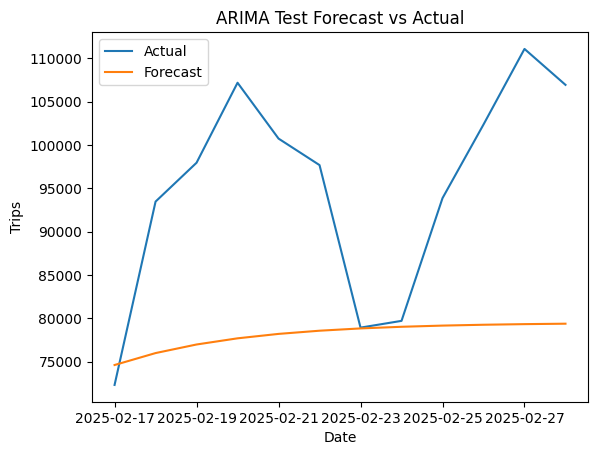

In [76]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(test_arima.index, test_arima, label="Actual")
plt.plot(test_arima.index, forecast_test, label="Forecast")
plt.legend()
plt.title("ARIMA Test Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

## Model Evaluation Summary

The evaluation results demonstrate that each model serves a distinct purpose:

- K-Means clustering effectively identifies meaningful patterns in taxi trip behavior, as indicated by a high silhouette score.
- The Decision Tree model shows reliable predictive performance with consistent results on both training and test data.
- The ARIMA model captures the overall demand trend but produces smoother forecasts, highlighting limitations in modeling short-term variability.

Together, these models provide a comprehensive analysis of taxi demand from pattern discovery to prediction and forecasting.

In [77]:
file_path3 = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2025-03.parquet"
file_path4 = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2025-04.parquet"
file_path5 = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2025-05.parquet"

df3 = spark.read.parquet(file_path3)
df4 = spark.read.parquet(file_path4)
df5 = spark.read.parquet(file_path5)

# Combine all months
df_full = df1.union(df2).union(df3).union(df4).union(df5)

print("Total rows:", df_full.count())

Total rows: 19760424


In [78]:
from pyspark.sql.functions import col

df_clean_full = df_full.filter(
    (col("trip_distance") > 0) & (col("trip_distance") < 100) &
    (col("fare_amount") > 0) & (col("fare_amount") < 500) &
    (col("total_amount") > 0) & (col("total_amount") < 500) &
    (col("passenger_count") > 0)
)

In [79]:
from pyspark.sql.functions import to_date, count

df_time_full = df_clean_full.withColumn(
    "pickup_date",
    to_date("tpep_pickup_datetime")
)

daily_demand_full = df_time_full.groupBy("pickup_date") \
    .agg(count("*").alias("trip_count")) \
    .orderBy("pickup_date")

In [80]:
pdf_full = daily_demand_full.toPandas()

import pandas as pd

pdf_full["pickup_date"] = pd.to_datetime(pdf_full["pickup_date"])
pdf_full.set_index("pickup_date", inplace=True)

pdf_full = pdf_full.asfreq("D")
pdf_full["trip_count"] = pdf_full["trip_count"].interpolate()

In [83]:
pdf_full = daily_demand_full.toPandas()

import pandas as pd

pdf_full["pickup_date"] = pd.to_datetime(pdf_full["pickup_date"])
pdf_full = pdf_full.sort_values("pickup_date")

# Keep only Jan–May 2025
pdf_full = pdf_full[
    (pdf_full["pickup_date"] >= "2025-01-01") &
    (pdf_full["pickup_date"] <= "2025-05-31")
]

pdf_full.set_index("pickup_date", inplace=True)

# Daily frequency only inside correct range
pdf_full = pdf_full.asfreq("D")

# Fill missing values
pdf_full["trip_count"] = pdf_full["trip_count"].interpolate()

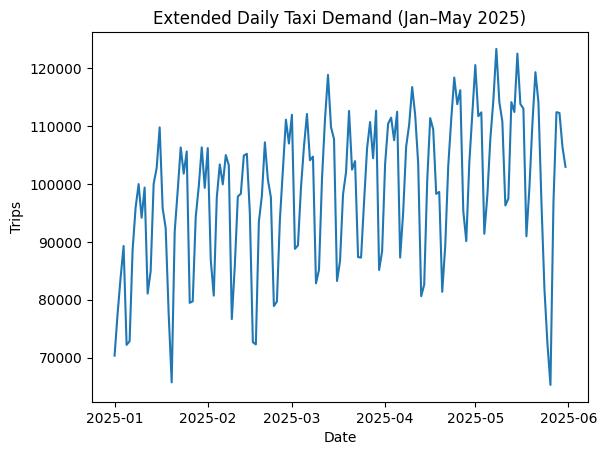

In [84]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(pdf_full.index, pdf_full["trip_count"])
plt.title("Extended Daily Taxi Demand (Jan–May 2025)")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

In [85]:
from statsmodels.tsa.arima.model import ARIMA

model_full = ARIMA(pdf_full["trip_count"], order=(1,1,1))
model_fit_full = model_full.fit()

print(model_fit_full.summary())

                               SARIMAX Results                                
Dep. Variable:             trip_count   No. Observations:                  151
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1614.482
Date:                Sat, 09 May 2026   AIC                           3234.964
Time:                        22:12:10   BIC                           3243.996
Sample:                    01-01-2025   HQIC                          3238.633
                         - 05-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1791      0.796     -0.225      0.822      -1.739       1.381
ma.L1          0.2684      0.756      0.355      0.722      -1.213       1.750
sigma2      1.223e+08   6.07e-09   2.01e+16      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [86]:
forecast_full = model_fit_full.forecast(steps=7)

print(forecast_full)

2025-06-01    102756.640282
2025-06-02    102788.220634
2025-06-03    102782.565609
2025-06-04    102783.578242
2025-06-05    102783.396912
2025-06-06    102783.429382
2025-06-07    102783.423568
Freq: D, Name: predicted_mean, dtype: float64


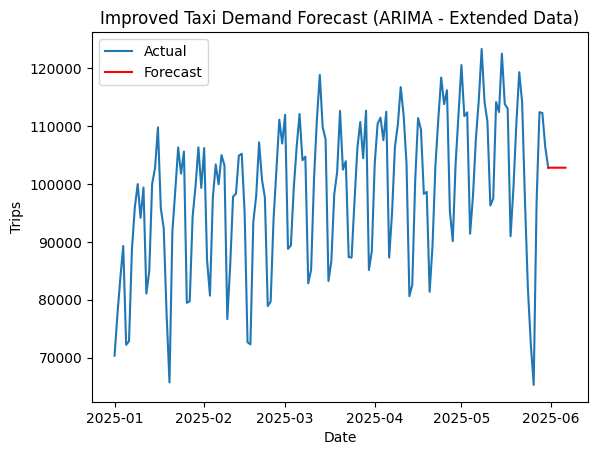

In [87]:
import matplotlib.pyplot as plt
import pandas as pd

plt.figure()

# Actual data
plt.plot(pdf_full.index, pdf_full["trip_count"], label="Actual")

# Forecast
plt.plot(
    pd.date_range(pdf_full.index[-1], periods=7, freq='D'),
    forecast_full,
    label="Forecast",
    color='red'
)

plt.legend()
plt.title("Improved Taxi Demand Forecast (ARIMA - Extended Data)")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

## Improved ARIMA Model with Extended Data

The ARIMA model was retrained using an extended dataset covering five months of taxi trip data. Increasing the number of observations from 59 to 151 days improved the model’s ability to capture overall demand trends.

The model produced statistically acceptable results, as indicated by the Ljung-Box test, suggesting that residual autocorrelation is minimal.

However, the model still produces relatively smooth forecasts and does not fully capture the strong weekly fluctuations observed in the data. This suggests the presence of seasonal patterns that are not explicitly modeled in the current ARIMA configuration.

Future work may involve using Seasonal ARIMA (SARIMA) to better capture periodic demand variations.